<a href="https://colab.research.google.com/github/0110225150-hub/ti05_salma_0110225150/blob/main/MLmandiri4_Salma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, RocCurveDisplay, ConfusionMatrixDisplay
)

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


##Membaca Dataset

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/ML 2026/Praktikum04/data/calonpembelimobil.csv')
df.head()

,ID,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan,Beli_Mobil
0,1,32,1,0,0,240,1
1,2,49,2,1,1,100,0
2,3,52,1,0,2,250,1
3,4,26,2,1,1,130,0
4,5,45,3,0,2,237,1


##Informasi Umum Dataset

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   ID              1000 non-null   int64
 1   Usia            1000 non-null   int64
 2   Status          1000 non-null   int64
 3   Kelamin         1000 non-null   int64
 4   Memiliki_Mobil  1000 non-null   int64
 5   Penghasilan     1000 non-null   int64
 6   Beli_Mobil      1000 non-null   int64
dtypes: int64(7)
memory usage: 54.8 KB


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
print("Distribusi Target (Beli_Mobil):")
print(df['Beli_Mobil'].value_counts())

Distribusi Target (Beli_Mobil):
Beli_Mobil
1    633
0    367
Name: count, dtype: int64


In [ ]:
df.isnull().sum()

,0
ID,0
Usia,0
Status,0
Kelamin,0
Memiliki_Mobil,0
Penghasilan,0
Beli_Mobil,0


##Pre-Processing Data

In [ ]:
corr_matrix = df.corr(numeric_only=True)
corr_matrix

,ID,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan,Beli_Mobil
ID,1.000000,0.149779,-0.006634,0.014646,0.068555,0.254177,0.168614
Usia,0.149779,1.000000,0.051476,0.019454,0.090926,0.125859,0.100127
Status,-0.006634,0.051476,1.000000,-0.008561,0.048302,0.071714,0.048584
Kelamin,0.014646,0.019454,-0.008561,1.000000,0.035199,-0.054211,-0.147301
Memiliki_Mobil,0.068555,0.090926,0.048302,0.035199,1.000000,0.137823,0.102005
Penghasilan,0.254177,0.125859,0.071714,-0.054211,0.137823,1.000000,0.763930
Beli_Mobil,0.168614,0.100127,0.048584,-0.147301,0.102005,0.763930,1.000000


In [ ]:
numeric_cols = ['Usia', 'Status', 'Kelamin', 'Memiliki_Mobil', 'Penghasilan', 'Beli_Mobil']
corr_matrix = df[numeric_cols].corr()

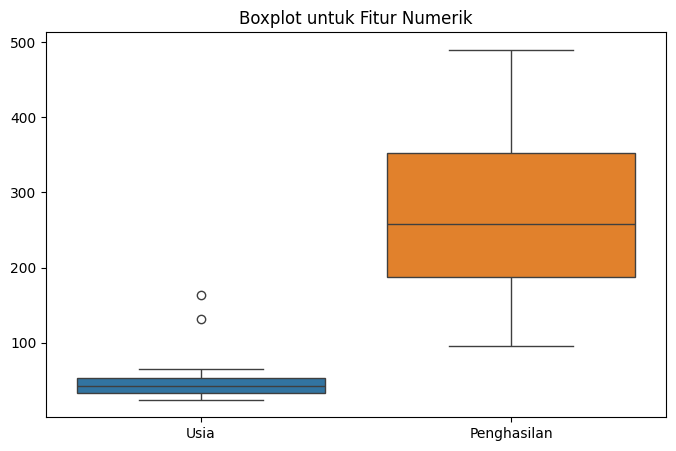

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.boxplot(data=df[['Usia', 'Penghasilan']])
plt.title("Boxplot untuk Fitur Numerik")
plt.show()

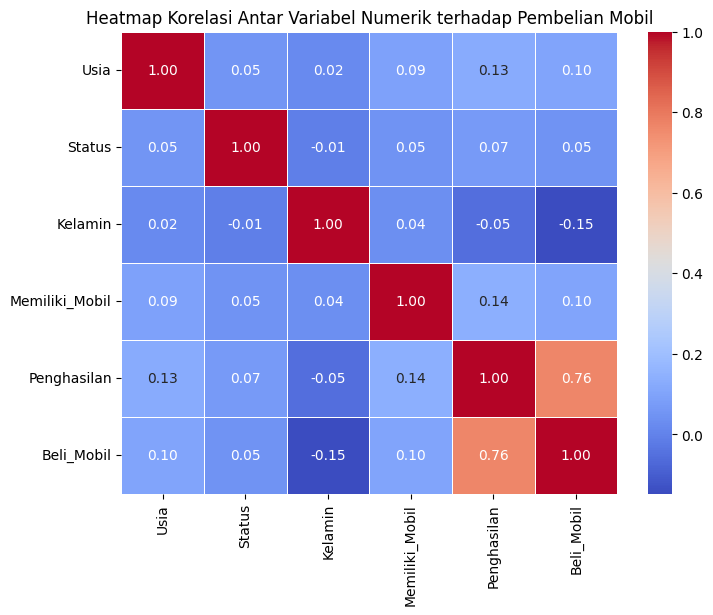

In [ ]:
# Visualisasi heatmap
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Heatmap Korelasi Antar Variabel Numerik terhadap Pembelian Mobil", fontsize=12)
plt.show()

##Pembagian Dataset

In [ ]:
X = df[['Usia', 'Status', 'Kelamin', 'Memiliki_Mobil', 'Penghasilan']]
y = df['Beli_Mobil']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data latih:", X_train.shape)
print("Data uji  :", X_test.shape)

Data latih: (800, 5)
Data uji  : (200, 5)


In [ ]:
feature_num = ['Usia', 'Penghasilan']
feature_passthrough = ['Status', 'Kelamin', 'Memiliki_Mobil']

preprocess = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), feature_num),
        ('passthrough', 'passthrough', feature_passthrough)
    ],
    remainder='drop'
)

model = LogisticRegression(
    max_iter=1000,
    solver='lbfgs',
    class_weight='balanced',
    random_state=42
)

clf = Pipeline([
    ('preprocess', preprocess),
    ('model', model)
])

clf.fit(X_train, y_train)
print("Model Logistic Regression berhasil dilatih.")

Model Logistic Regression berhasil dilatih.


##Pembangunan Model Logistic Regression

##Prediksi dan Evaluasi Model

In [ ]:
y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:, 1]

print(f"Akurasi   : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob):.4f}")

Akurasi   : 0.9300
Precision : 0.9829
Recall    : 0.9055
F1-Score  : 0.9426
ROC-AUC   : 0.9769


In [ ]:
print(f"Akurasi   : {accuracy_score(y_test, y_pred):.4f}")

Akurasi   : 0.9300


In [ ]:
print(f"Precision : {precision_score(y_test, y_pred, zero_division=0):.4f}")

Precision : 0.9829


In [ ]:
print(f"Recall    : {recall_score(y_test, y_pred, zero_division=0):.4f}")

Recall    : 0.9055


In [ ]:
print(f"F1-Score  : {f1_score(y_test, y_pred, zero_division=0):.4f}")

F1-Score  : 0.9426


##Prediksi Hasil Evaluasi

<Figure size 600x400 with 0 Axes>

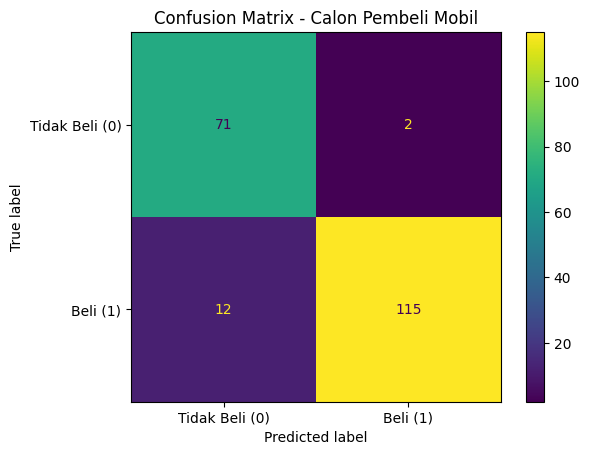

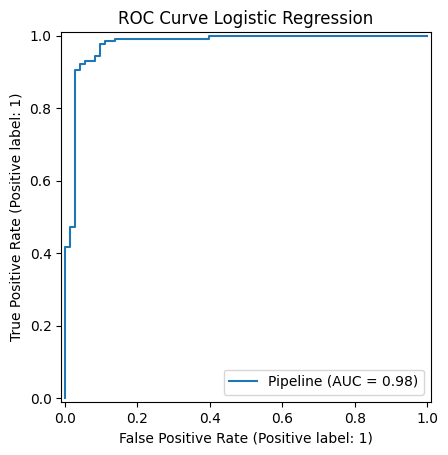

In [ ]:
plt.figure(figsize=(6, 4))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred),
    display_labels=['Tidak Beli (0)', 'Beli (1)']
).plot(values_format='d')
plt.title("Confusion Matrix - Calon Pembeli Mobil")
plt.show()

RocCurveDisplay.from_estimator(clf, X_test, y_test)
plt.title("ROC Curve Logistic Regression")
plt.show()

##Classification Report

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, target_names=['Tidak Beli (0)', 'Beli (1)']))

                precision    recall  f1-score   support

Tidak Beli (0)       0.86      0.97      0.91        73
      Beli (1)       0.98      0.91      0.94       127

      accuracy                           0.93       200
     macro avg       0.92      0.94      0.93       200
  weighted avg       0.94      0.93      0.93       200



##Cross Validation

In [ ]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(clf, X, y, cv=5)

print("Skor tiap fold  :", scores)
print("Rata-rata akurasi:", np.mean(scores))
print("Standar deviasi :", np.std(scores))

Skor tiap fold  : [0.775 0.915 0.955 0.945 0.94 ]
Rata-rata akurasi: 0.9059999999999999
Standar deviasi : 0.06681317235396023


In [ ]:
fitur_names = feature_num + feature_passthrough
coefs = clf.named_steps['model'].coef_[0]
odds = np.exp(coefs)

coef_df = pd.DataFrame({
    'Fitur': fitur_names,
    'Koefisien (log-odds)': coefs,
    'Odds Ratio (e^coef)': odds
}).sort_values('Odds Ratio (e^coef)', ascending=False)

display(coef_df)

,Fitur,Koefisien (log-odds),Odds Ratio (e^coef)
1,Penghasilan,4.550296,94.660404
4,Memiliki_Mobil,0.094958,1.099613
0,Usia,-0.046660,0.954412
2,Status,-0.124292,0.883122
3,Kelamin,-1.130837,0.322763


In [ ]:
data_baru = pd.DataFrame({
    'Usia': [25, 48, 35],
    'Status': [1, 2, 3],
    'Kelamin': [0, 1, 0],
    'Memiliki_Mobil': [0, 1, 2],
    'Penghasilan': [120, 260, 210]
})

pred_baru = clf.predict(data_baru)
prob_baru = clf.predict_proba(data_baru)[:, 1]

hasil_baru = data_baru.copy()
hasil_baru['Prob_Beli'] = prob_baru
hasil_baru['Pred_Beli (0=Tidak, 1=Ya)'] = pred_baru

display(hasil_baru)

,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan,Prob_Beli,"Pred_Beli (0=Tidak, 1=Ya)"
0,25,1,0,0,120,0.008479,0
1,48,2,1,1,260,0.673400,1
2,35,3,0,2,210,0.370333,0
